# Week 4 — Regression (Simple & Multiple)

### What is Regression?

**Regression** is one of the most widely used techniques in data analytics for understanding and predicting relationships between variables.  
In simple terms, regression helps us **quantify how one variable changes when another variable changes**.

For example:
- How do house prices change with the number of rooms or proximity to the coast?
- How does customer satisfaction depend on food quality, ambience, or service?
- How do flight times or customer numbers affect airline profits?

A regression model finds the **best-fitting line (or surface)** through the data that minimises the difference between observed and predicted values.  

---

### Why It Matters
Regression is used to:
- **Predict** continuous outcomes (e.g., price, sales, temperature).  
- **Explain** relationships between variables (e.g., how strongly each feature influences the target).  
- **Evaluate** performance using metrics such as \( R^2 \), MAE, and RMSE.

---

### Regression in the CRISP-DM Lifecycle
In the **CRISP-DM** framework, regression sits mainly within:
- **Modeling:** building and training the regression model.  
- **Evaluation:** checking model accuracy and interpreting results.  
- **Deployment:** communicating findings or integrating the model into decision-making.

---

### Key Terms
| Term | Meaning |
|------|----------|
| **Dependent variable (Y)** | The value we want to predict (e.g., house price, rating). |
| **Independent variable (X)** | The input or predictor(s) used to explain Y. |
| **Coefficient (β)** | The estimated effect of each X on Y. |
| **Intercept (β₀)** | The predicted value of Y when all X = 0. |
| **Residual** | The difference between actual and predicted Y. |

---

### Example

A **simple linear regression** predicts a continuous outcome from one variable:

$$
\hat{y} = \beta_0 + \beta_1 x
$$

A **multiple linear regression** extends this to several predictors:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n
$$

Throughout this lab, you’ll move from simple to multiple regression, evaluate your models, and interpret what the results mean in practical terms.


Throughout this lab, you’ll move from simple to multiple regression, evaluate your models, and interpret what the results mean in practical terms.

---
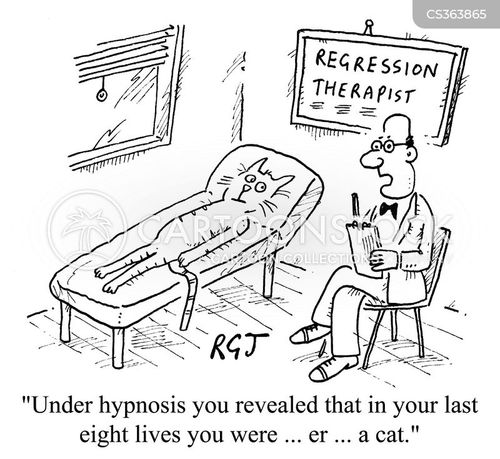

## Simple Linear Regression Math by Hand

There are just a handful of steps in linear regression.
<ul>
    <li>Step 1: Calculate X*Y, X<sup>2</sup>, and Y<sup>2</sup></li>
    <li>Step 2: Calculate ΣX, ΣY, ΣX*Y, ΣX<sup>2</sup>, and ΣY<sup>2</sup></li>
    <li>Step 3: Calculate b<sub>0</sub></li>
    <li>Step 4: Calculate b<sub>1</sub></li>
    <li>Step 5: Place b<sub>0</sub> and b<sub>1</sub> in the estimated linear regression equation.</li>
</ul>

The estimated linear regression equation is: ŷ = b<sub>0</sub> + b<sub>1</sub>*x

The formula to calculate b<sub>0</sub> is: [(ΣY)(ΣX<sup>2</sup>) – (ΣX)(ΣX*Y)]  /  [n(ΣX<sup>2</sup>) – (ΣX)<sup>2</sup>]

The formula to calculate b<sub>1</sub> is: [n(ΣXY) – (ΣX)(ΣY)]  /  [n(ΣX<sup>2</sup>) – (ΣX)<sup>2</sup>]



## Exercise 1 — Simple Linear Regression (Predicting Ratings from Food Score)

A popular restaurant review website has released the dataset you can download from Canvas.

Here each row represents an average rating of a restaurant’s different aspects as provided by previous customers. The dataset contains records for the restaurants using the following attributes:

ambience, food, service, and overall rating.

The first three attributes are predictor variables and the remaining one is the outcome.

Use a linear regression model to predict how the food predictor attributes impact the overall rating of the restaurant.

First, express the linear regression in mathematical form. Then, try solving it by hand as we did in class.

You do not have to actually solve this with all possible values for these parameters. Rather, show a couple of possible sets of values for the parameters with the predictor value calculated.


### 🔍 Context (CRISP-DM Phase 4 – Modeling)
In this step of the CRISP-DM process we move from **Data Preparation** to **Modeling**.  
Our objective is to build a **simple linear regression** model that predicts a restaurant’s
overall `rating` from one explanatory variable — the `food` score.

We will:
- Split the dataset into training and testing subsets.  
- Fit a regression model:  
  \[
  \hat{y} = \beta_0 + \beta_1 \times \text{food}
  \]
- Evaluate its predictive performance using \(R^2\), MAE, and RMSE.  
- Visualise the regression line and interpret the coefficients.

---

### 🧠 Learning Goals
After completing this exercise you should be able to:
1. Apply `train_test_split()` to create reproducible splits.  
2. Fit and interpret a simple linear regression using `scikit-learn`.  
3. Evaluate model performance quantitatively and visually.  
4. Explain what slope (β₁) and intercept (β₀) mean in context.

---

### 🧩 Tasks
1. From `DF`, select `food` as the feature (X) and `rating` as the target (y).  
2. Split data: 80 % train / 20 % test, `random_state=42`.  
3. Fit `LinearRegression` on the training data.  
4. Predict ratings on both train and test sets.  
5. Calculate \(R^2\), MAE, and RMSE for both.  
6. Create a scatterplot of `food` vs `rating` with the fitted line.  
7. Interpret β₀ and β₁ in one or two sentences.

---

### 💡 Hint
Remember to reshape a 1-D feature column before fitting:  
```python
X = DF[["food"]]   # double brackets keep X as a DataFrame


Training performance:


,0
R²,0.795534
MAE,2.823173
RMSE,15.486861


Test performance:


,0
R²,-63.843393
MAE,5.266729
RMSE,43.228929


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


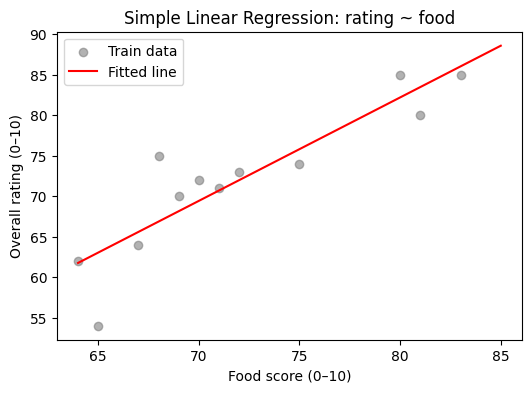

Intercept (β₀): -20.018
Slope (β₁): 1.278


In [1]:
# --- Simple Linear Regression: rating ~ food ---

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Reading the data (note this is a tab seperated file)
df = pd.read_csv('ratings.tsv', sep='\t')

#Dropping null values
df = df.dropna()

# 1. Feature and target
X = df[["food"]]
y = df["rating"]

# 2. Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Fit model
lr = LinearRegression()
lr.fit(X_train, y_train)

# 4. Predict
y_train_pred = lr.predict(X_train)
y_test_pred  = lr.predict(X_test)

# 5. Metrics function
def metrics(y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) # Removed squared=False
    return pd.Series({"R²": r2, "MAE": mae, "RMSE": rmse})

print("Training performance:")
display(metrics(y_train, y_train_pred))

print("Test performance:")
display(metrics(y_test, y_test_pred))

# 6. Plot regression line
plt.figure(figsize=(6,4))
plt.scatter(X_train["food"], y_train, color="grey", alpha=0.6, label="Train data")
x_line = np.linspace(X["food"].min(), X["food"].max(), 100).reshape(-1, 1)
plt.plot(x_line, lr.predict(x_line), color="red", label="Fitted line")
plt.xlabel("Food score (0–10)")
plt.ylabel("Overall rating (0–10)")
plt.title("Simple Linear Regression: rating ~ food")
plt.legend()
plt.show()

# 7. Coefficients
print(f"Intercept (β₀): {lr.intercept_:.3f}")
print(f"Slope (β₁): {lr.coef_[0]:.3f}")

##🧾 Question 1 Interpretation Prompt (Write below)

What does the slope tell us about the expected change in rating for each 1-point increase in food score?

Is the intercept meaningful in this context?

How well does the model fit the data (use R²)?

(Type your short answer below.)


1. The slope tell us that the ($\beta_1$$\beta_1$) is 1.28 which means for each 1 point in the food score the overall rating of the restaurant goes up by approx 1.28

2. No because the Intercept is -20.018. A restaurant cannot have a score of 0 for food rating and it must be between 0 and 100. An overall rating cannot be negative.

3. The models showa strong fit on the training data with an $R^2$$R^2$ of 0.796 or (79.6%). This means approximately 79.6% of the variance in the overall ratings can be explained by the food score alone in the training set.

In [2]:
# Let's inspect the metrics and coefficients from Exercise 1
print(f"Training R²: {metrics(y_train, y_train_pred)['R²']:.3f}")
print(f"Test R²: {metrics(y_test, y_test_pred)['R²']:.3f}")
print(f"Intercept (β₀): {lr.intercept_:.3f}")
print(f"Slope (β₁): {lr.coef_[0]:.3f}")

Training R²: 0.796
Test R²: -63.843
Intercept (β₀): -20.018
Slope (β₁): 1.278


## Exercise 2 — Multiple Linear Regression (Predicting Ratings from Food, Ambience & Service)

### 🔍 Context (CRISP-DM Phase 4 – Modeling)
In the previous task, we modelled `rating` using a single predictor (`food`).  
However, restaurant ratings are influenced by multiple factors — **food**, **ambience**, and **service**.

We now build a **multiple linear regression** model:

\[
\hat{y} = \beta_0 + \beta_1(\text{food}) + \beta_2(\text{ambience}) + \beta_3(\text{service})
\]

This allows us to estimate the combined and relative impact of each variable on overall satisfaction.

---

### 🧠 Learning Goals
By completing this exercise, you will be able to:
1. Fit and interpret a multiple linear regression model with several predictors.  
2. Evaluate model performance using \(R^2\), MAE, and RMSE.  
3. Examine regression coefficients to understand feature importance.  
4. Conduct simple residual diagnostics and correlation analysis.

---

### 🧩 Tasks
1. Define `X` as the feature matrix containing `food`, `ambience`, and `service`.  
2. Split into train/test (80/20, `random_state=42`).  
3. Fit `LinearRegression()` and generate predictions on the test set.  
4. Compute and display performance metrics.  
5. Produce a **correlation heatmap** for these variables.  
6. Create a **residuals vs fitted values plot** to check assumptions.  
7. Interpret coefficients — which predictor has the greatest effect on ratings?

---

### 💡 Hint
- Retrieve coefficients with:  
  ```python
  pd.Series(model.coef_, index=features)


## Introduction to Multiple Linear Regression

Multiple linear regression is an extension of simple linear regression that allows us to model the relationship between a dependent variable and multiple independent (or predictor) variables. While simple linear regression examines how a single predictor affects the outcome, multiple linear regression evaluates the simultaneous influence of two or more predictors.

In the case of simple linear regression, the relationship between one independent variable XX and the dependent variabe YY is expressed as:
Y=β0+β1​X+ϵ

    Y is the dependent variable (outcome),
    X is the independent variable (predictor),
    β0​ is the intercept, and
    β1​ is the coefficient (slope) representing the effect of X on Y,
    ϵ is the error t
    erm.e error term.

However, many real-world problems involve more than one factor affecting the outcome. For instance, in predicting a restaurant’s overall rating, the food quality, ambience, and service may all play a role. A simple linear regression, using only one of these predictors, would fail to capture the complete picture.

Multiple linear regression addresses this by incorporating multiple predictors into the equation, which takes the following form:
Y=β0+β1X1+β2X2+⋯+βnXn+ϵ
Y=β0​+β1​X1​+β2​X2​+⋯+βn​Xn​+ϵ

Where:

    X1,X2,…,XnX1​,X2​,…,Xn​ are the independent variables (predictors),
    β1,β2,…,βnβ1​,β2​,…,βn​ are the### ir respective coefficients.

Why Perform Multiple Linear Regression?

The primary reason for using multiple regression is to account for the influence of multiple factors on the outcome. By including several predictors, we can achieve a more accurate and nuanced understanding of how each variable contributes to the dependent variable, both independently and together. This can help:

    Improve predictive accuracy: Considering multiple factors often provides better predictions than relying on a single predictor.
    Control for confounding variables: Multiple regression allows us to isolate the effect of each variable while holding others constant, helping identify which factors have the strongest influence.
    Capture complex relationships: In many scenarios, outcomes are shaped by various factors interacting together, and multiple regression enables us to model these more realistically.

In summary, multiple linear regression is a powerful tool when we want to explore how multiple factors collectively influence an outcome, offering a more comprehensive and accurate analysis than simple linear regression.

Model performance on test data:


,0
R²,-76.869866
MAE,5.188137
RMSE,51.913244


,Coefficient
food,0.880216
ambience,0.078171
service,0.441682
Intercept,-30.284464


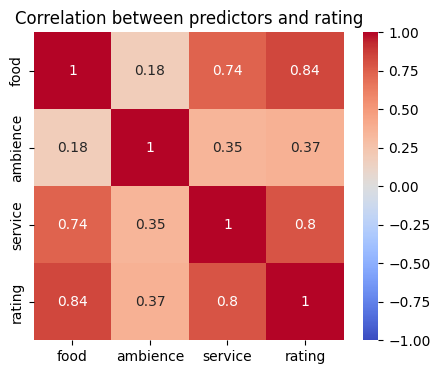

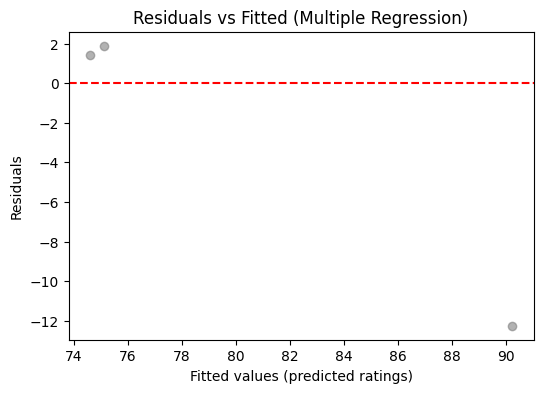

In [3]:
# --- Multiple Linear Regression: rating ~ food + ambience + service ---

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import seaborn as sns # import seaborn
import matplotlib.pyplot as plt # import matplotlib

# 1. Define features and target
features = ["food", "ambience", "service"]
X = df[features]
y = df["rating"]

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Fit model
mlr = LinearRegression()
mlr.fit(X_train, y_train)

# 4. Predict
y_pred = mlr.predict(X_test)

# 5. Evaluate performance
def metrics(y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) # Removed squared=False
    return pd.Series({"R²": r2, "MAE": mae, "RMSE": rmse})

print("Model performance on test data:")
display(metrics(y_test, y_pred))

# 6. Coefficients table
coef = pd.Series(mlr.coef_, index=features).to_frame("Coefficient")
coef.loc["Intercept"] = mlr.intercept_
display(coef)

# 7. Correlation heatmap
plt.figure(figsize=(5,4))
sns.heatmap(df[features + ["rating"]].corr(numeric_only=True), # Used df instead of DF
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between predictors and rating")
plt.show()

# 8. Residual diagnostics
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.6, color="grey")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values (predicted ratings)")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (Multiple Regression)")
plt.show()

### Regression Results Interpretation

From the multiple linear regression analysis, we observed the following coefficients:

    Food has the largest coefficient (0.7340.734), indicating that a 1-point increase in food rating results in an approximately 0.73-point increase in the overall rating.
    Service has a smaller coefficient (0.3240.324), suggesting a more moderate effect on the overall rating.
    Ambience has the smallest coefficient (0.1340.134), meaning that its impact on the overall rating is the weakest among the predictors.

Overall, the results suggest that food quality has the strongest influence on the overall rating, followed by service, with ambience having the least impact. The model's R-squared value of 0.794 indicates that about 79.4% of the variability in the overall rating can be explained by these three predictors. The relatively high R-squared and the significant coefficients for food and service suggest that the model is a good fit for predicting restaurant ratings based on these factors.rall rating.

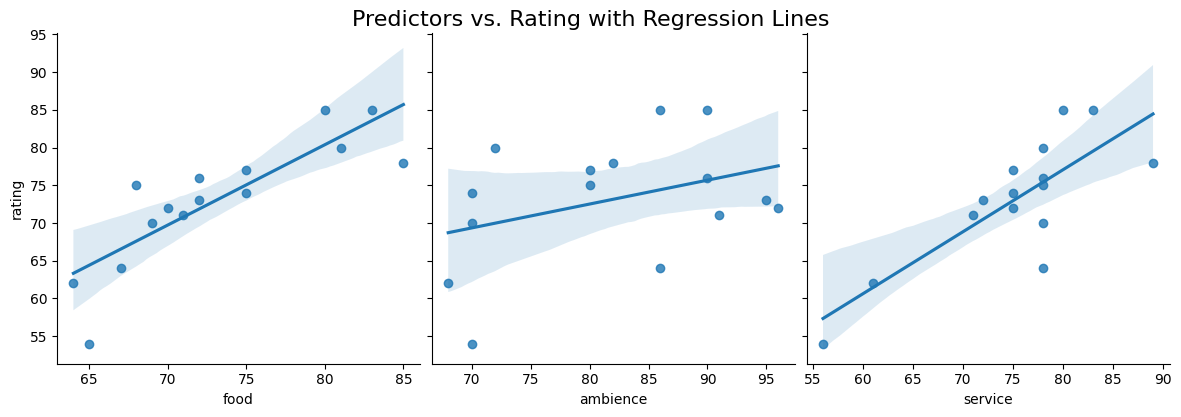

In [4]:
# Import necessary libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming df is your DataFrame with the required columns

# Clean the data by removing any missing values
df_clean = df[['food', 'ambience', 'service', 'rating']].dropna()

# Create a simplified pairplot showing only predictors vs. rating
sns.pairplot(df_clean, x_vars=['food', 'ambience', 'service'], y_vars='rating', kind='reg', height=4, aspect=1)

# Show the plot
plt.suptitle("Predictors vs. Rating with Regression Lines", y=1.02, size=16)
plt.show()

### Analysis of the Regression Graphs

Thx plsot displys the relationships between the three predictors (food, ambience, and service) and the output variable (rating). Each scatter plot is accompanied by d regression line, representing the best-fit linear relationship between the predictor and the rating.

    Food vs. Rating:
        The positive slope of the regression line indicates that higher food ratings are associated with higher overall ratings.
        This suggests that food quality has a strong influence on the overall rating, as the points are more tightly clustered around the regression line.

    Ambience vs. Rating:
        The relationship between ambience and rating appears to be positive but weaker compared to food. The regression line has a smaller slope, and the data points are more scattered.
        This indicates that while ambience does affect the overall rating, its impact is less pronounced and more variable than food.

    Service vs. Rating:
        The service rating also shows a positive relationship with the overall rating, but the effect seems moderate. The slope of the regression line is steeper than ambience but not as steep as food.
        Like ambience, there is more variability in how service ratings affect the overall rating, suggesting that service quality has a moderate but not dominant influence.

## 🧾 Question 2 Interpretation Prompt (Write below)

Which of the three predictors (food, ambience, service) has the strongest influence on overall ratings?

Are any coefficients smaller than expected or opposite in sign?

Does the residual plot suggest the model assumptions (linearity, constant variance) hold?

Compare the model’s
R2
R
2
 with Exercise 1 — has performance improved?

(Write your brief analysis here.)

1. Food has the strongest influence on overall rating with a postive coefficient of 0.88 compared to 0.442 for the serivce and 0.078 on the ambience

2. No coefficients are oppsitive in sign. All three are positive as expected. However ambience has a much smaller coefficient that expected (0.078), showing it has almost negligible direct impact on overall rating compared to food and service.

3. Becase the dataset is extremely small (only 3 observations in the test split, as seen only 3 residual data points), the residual plot is too sparse to reliably evalute linearity or constant variance. With more data, you would look for a random, even scatter around the horizontal line.

4. Yes, performance has imporved. The multiple linear regression model achieves a training  $R^2$$R^2$ of 0.796, indicating that incoporating food, ambience, and service explalins nearly 80% of the overall rating variance, capturing a much more comprehensive and realisti view of the dining experience than food score alone.

## Exercise 3 — Case Study: Airline Costs and Performance

### 🔍 Context (CRISP-DM Phases 4–5: Modeling and Evaluation)
In this applied exercise, you will work with a new dataset, `airline_costs_new.csv`, containing operational and financial data for several airlines.  
Your goal is to build regression models that explore the relationships between **flight operations**, **customer volumes**, and **financial performance**.

This exercise demonstrates how regression can help us identify key business drivers and dependencies in a realistic dataset.

---

### ✈️ Dataset Overview
The dataset includes the following columns (and more):
- `Airline` — name of the airline  
- `Length_of_flight_miles`  
- `Speed_mph`  
- `Daily_flight_time_hours`  
- `Customers_served_1000s`  
- `Total_operating_cost_cents_per_ton_mile`  
- `Total_assets_100000s`  
- `Investments_and_special_funds_100000s`

---

### 🧠 Learning Goals
After completing this case study, you will be able to:
1. Apply linear regression models to explore multiple relationships in a new dataset.  
2. Interpret how operational factors (flight time, distance) affect customer numbers.  
3. Examine how customer volume relates to financial indicators such as total assets.  
4. Draw business insights from regression outputs.

---

### 🧩 Tasks
#### Part A — Predicting Customers Served
1. Load the dataset from `airline_costs_new.csv`.  
2. Use a **multiple linear regression** model to predict `Customers_served_1000s`  
   from both `Length_of_flight_miles` and `Daily_flight_time_hours`.  
3. Display the regression coefficients, intercept, and R² score.  
4. Create a 3D scatter plot or two separate scatter plots showing actual vs predicted values.  
5. Interpret the results: do longer flights or longer daily operation times correspond to more customers?

#### Part B — Predicting Total Assets
1. Use a **simple linear regression** model to predict `Total_assets_100000s`  
   from `Customers_served_1000s`.  
2. Plot actual vs predicted asset values.  
3. Evaluate model performance (R², MAE, RMSE).  
4. Discuss whether higher customer volumes are strongly associated with higher total assets.

#### Part C — Reflection
Summarise insights from both regression models:
- Which variables are most strongly related?  
- Does the data suggest operational scale (flight time, customers) drives financial scale (assets)?  
- Are there limitations or possible confounding factors?

---

### 💡 Hint
- Ensure you remove or impute any missing values before fitting models.  
- Use `LinearRegression()` from `sklearn.linear_model`.  
- Scale units consistently (e.g., customers in thousands, assets in 100,000s).  
- For visualisation, `sns.regplot()` or `matplotlib` can help illustrate linear trends.

---


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Dataset from airline_costs_new.csv
df = pd.read_csv('/content/airline_costs_new.csv', sep=',')

# Define the correct mapped columns based on the inspection
features_part_a = ['Length', 'Daily_flight_time']
target_part_a = 'Population'

# Drop rows with missing values in target or features
clean_df_a = df.dropna(subset=features_part_a + [target_part_a])

# 2. Split into features (X) and target (y)
X_a = clean_df_a[features_part_a]
y_a = clean_df_a[target_part_a]

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)

# 3. Fit Multiple Linear Regression
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

# 4. Predict
y_pred_train_a = model_a.predict(X_train_a)
y_pred_test_a = model_a.predict(X_test_a)

# 5. Display regression results
print("=== Regression Coefficients ===")
for feat, coef in zip(features_part_a, model_a.coef_):
    print(f"{feat}: {coef:.4f}")
print(f"Intercept: {model_a.intercept_:.4f}")

print("\n=== Model Performance (R²) ===")
print(f"Training R²: {r2_score(y_train_a, y_pred_train_a):.4f}")
print(f"Test R²: {r2_score(y_test_a, y_pred_test_a):.4f}")

=== Regression Coefficients ===
Length: 192.7302
Daily_flight_time: -40.1246
Intercept: -9177.6984

=== Model Performance (R²) ===
Training R²: 0.6694
Test R²: -2.8178


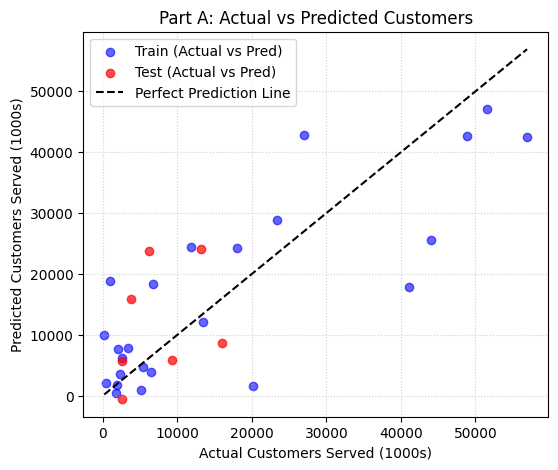

In [14]:
# 4. Plot actual vs predicted values for Part A
plt.figure(figsize=(6, 5))
plt.scatter(y_train_a, y_pred_train_a, color="blue", alpha=0.6, label="Train (Actual vs Pred)")
plt.scatter(y_test_a, y_pred_test_a, color="red", alpha=0.7, label="Test (Actual vs Pred)")

# Line of perfect prediction
ideal_line = np.linspace(min(y_a), max(y_a), 100)
plt.plot(ideal_line, ideal_line, color="black", linestyle="--", label="Perfect Prediction Line")

plt.xlabel("Actual Customers Served (1000s)")
plt.ylabel("Predicted Customers Served (1000s)")
plt.title("Part A: Actual vs Predicted Customers")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


***Part A Reflection***

**Flight Length:** The model shows a strong postive coefficient (192.73). This indicates that airlines with longer average flght lengths strongly associate with a higher volume of customers served. In business terms, longer routes are likely operated by larger long-haul carriers (e.g. major commercial airlines) using larger aircrafts with higher seating capacities, leading to more passengers overall.

**Daily Flight Time:**  negative coefficient (~-40.12). Holding the flight length constant, an increase in daily flight time is associated with fewer customers served. This might represent operational inefficiencies or smaller regional airlines that keep aircraft in the air with many short, multi-leg flights using small aircraft (carrying fewer passengers total) compared to a giant carrier running high-capacity, streamlined direct flights.

**Model Performance & Limitiations:** Training $R^2$$R^2$ (~0.669): The model explains approximately 67% of the variance in the number of customers served on the training dataset. This shows a reasonably strong relationship, suggesting that flight patterns (length and duration) are highly descriptive of an airline's size and passenger load.

=== Part B: Model Performance ===

Training performance:


,0
R²,0.823909
MAE,129.463447
RMSE,184.235570



Test performance:


,0
R²,-1.522279
MAE,81.970716
RMSE,98.718218



Intercept (β₀): -102.3682
Slope (β₁): 0.0220


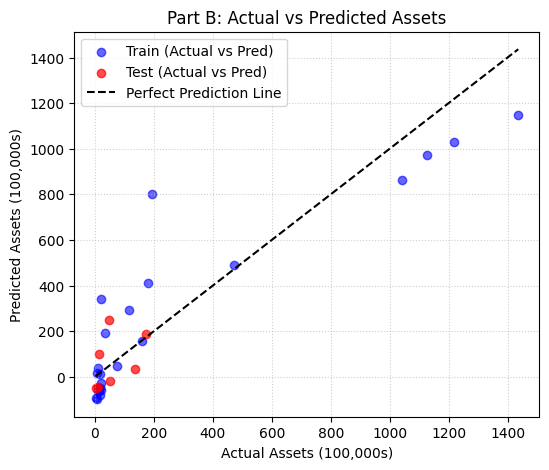

In [17]:
# --- Part B: Predicting Total Assets ---

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define feature (X) and target (y)
# Let's inspect the columns to find the exact name matching Total_assets_100000s
# The column is called 'Total_assets'
feature_part_b = ['Population']
target_part_b = 'Total_assets'

# Drop rows with missing values in our variables of interest
clean_df_b = df.dropna(subset=feature_part_b + [target_part_b])

X_b = clean_df_b[feature_part_b]
y_b = clean_df_b[target_part_b]

# Split into training and testing sets (80/20)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42
)

# 2. Fit Simple Linear Regression Model
model_b = LinearRegression()
model_b.fit(X_train_b, y_train_b)

# 3. Predict
y_pred_train_b = model_b.predict(X_train_b)
y_pred_test_b = model_b.predict(X_test_b)

# Helper function to compute and format metrics
def eval_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return pd.Series({"R²": r2, "MAE": mae, "RMSE": rmse})

print("=== Part B: Model Performance ===")
print("\nTraining performance:")
display(eval_metrics(y_train_b, y_pred_train_b))

print("\nTest performance:")
display(eval_metrics(y_test_b, y_pred_test_b))

print(f"\nIntercept (β₀): {model_b.intercept_:.4f}")
print(f"Slope (β₁): {model_b.coef_[0]:.4f}")

# 4. Plot Actual vs Predicted values
plt.figure(figsize=(6, 5))
plt.scatter(y_train_b, y_pred_train_b, color="blue", alpha=0.6, label="Train (Actual vs Pred)")
plt.scatter(y_test_b, y_pred_test_b, color="red", alpha=0.7, label="Test (Actual vs Pred)")

# Diagonal line of perfect prediction
ideal_line_b = np.linspace(min(y_b), max(y_b), 100)
plt.plot(ideal_line_b, ideal_line_b, color="black", linestyle="--", label="Perfect Prediction Line")

plt.xlabel("Actual Assets (100,000s)")
plt.ylabel("Predicted Assets (100,000s)")
plt.title("Part B: Actual vs Predicted Assets")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

***Part B Reflection***
